In [2]:
import pandas as pd

df = pd.read_csv("../data/diamonds (1).csv")

# Remove CSV index column
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

display(df.head())

Dataset Shape: (53940, 10)

Columns:
['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Missing Values:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Duplicates:
146


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
# ============================================================
# DUPLICATE AUDIT
# ============================================================

# 1. Exact duplicate rows
exact_duplicates = df[df.duplicated(keep=False)].copy()

print("=" * 60)
print("EXACT DUPLICATE AUDIT")
print("=" * 60)

print("Total exact duplicate rows:", len(exact_duplicates))
print("Duplicate groups:", exact_duplicates.duplicated().sum())

# Show examples
display(
    exact_duplicates
    .sort_values(
        by=["carat", "cut", "color", "clarity", "price"]
    )
    .head(20)
)

# ------------------------------------------------------------
# 2. Check duplicates excluding price
# ------------------------------------------------------------

feature_columns = [
    "carat",
    "cut",
    "color",
    "clarity",
    "depth",
    "table",
    "x",
    "y",
    "z"
]

feature_duplicates = df[
    df.duplicated(
        subset=feature_columns,
        keep=False
    )
].copy()

print("\n" + "=" * 60)
print("DUPLICATES BASED ON FEATURES ONLY")
print("=" * 60)

print(
    "Rows having identical features:",
    len(feature_duplicates)
)

# ------------------------------------------------------------
# 3. Check whether same features have different prices
# ------------------------------------------------------------

price_conflicts = (
    feature_duplicates
    .groupby(feature_columns)["price"]
    .nunique()
)

conflicting_groups = price_conflicts[
    price_conflicts > 1
]

print(
    "\nFeature groups with multiple different prices:",
    len(conflicting_groups)
)

# ------------------------------------------------------------
# 4. Display examples
# ------------------------------------------------------------

if len(conflicting_groups) > 0:

    conflict_index = conflicting_groups.index

    conflict_examples = (
        feature_duplicates
        .set_index(feature_columns)
        .loc[conflict_index]
        .reset_index()
    )

    print("\nExamples of feature-price conflicts:")
    display(conflict_examples.head(20))

else:

    print(
        "\nNo feature-price conflicts found."
    )

EXACT DUPLICATE AUDIT
Total exact duplicate rows: 289
Duplicate groups: 146


,carat,cut,color,clarity,depth,table,price,x,y,z
43995,0.30,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
47296,0.30,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
34408,0.30,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
34422,0.30,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
28592,0.30,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71
28593,0.30,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71
31624,0.30,Ideal,H,SI1,62.2,57.0,450,4.26,4.29,2.66
31626,0.30,Ideal,H,SI1,62.2,57.0,450,4.27,4.28,2.66
31627,0.30,Ideal,H,SI1,62.2,57.0,450,4.26,4.29,2.66
31629,0.30,Ideal,H,SI1,62.2,57.0,450,4.27,4.28,2.66



DUPLICATES BASED ON FEATURES ONLY
Rows having identical features: 685

Feature groups with multiple different prices: 198

Examples of feature-price conflicts:


,carat,cut,color,clarity,depth,table,x,y,z,price
0,0.23,Good,F,VS2,63.8,57.0,3.93,3.84,2.48,357
1,0.23,Good,F,VS2,63.8,57.0,3.93,3.84,2.48,447
2,0.23,Good,G,VVS2,63.8,56.0,3.94,3.90,2.50,428
3,0.23,Good,G,VVS2,63.8,56.0,3.94,3.90,2.50,537
4,0.30,Good,E,VVS2,59.8,64.0,4.34,4.29,2.58,814
5,0.30,Good,E,VVS2,59.8,64.0,4.34,4.29,2.58,1026
6,0.30,Good,G,VS2,58.5,64.0,4.42,4.37,2.57,648
7,0.30,Good,G,VS2,58.5,64.0,4.42,4.37,2.57,515
8,0.30,Ideal,E,IF,61.1,57.0,4.31,4.33,2.64,957
9,0.30,Ideal,E,IF,61.1,57.0,4.31,4.33,2.64,1013


In [4]:
# ============================================================
# REMOVE EXACT DUPLICATES
# ============================================================

df_clean = df.drop_duplicates().reset_index(drop=True)

print("=" * 60)
print("DUPLICATE CLEANING")
print("=" * 60)

print(f"Original rows       : {len(df):,}")
print(f"Rows after cleaning : {len(df_clean):,}")
print(f"Rows removed        : {len(df) - len(df_clean):,}")

print("\nRemaining duplicates:")
print(df_clean.duplicated().sum())

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

DUPLICATE CLEANING
Original rows       : 53,940
Rows after cleaning : 53,794
Rows removed        : 146

Remaining duplicates:
0

Missing values:
0


PRICE DISTRIBUTION ANALYSIS
Mean   : 3933.07
Median : 2401.00
Std    : 3988.11
Min    : 326.00
Max    : 18823.00
Skewness: 1.6182


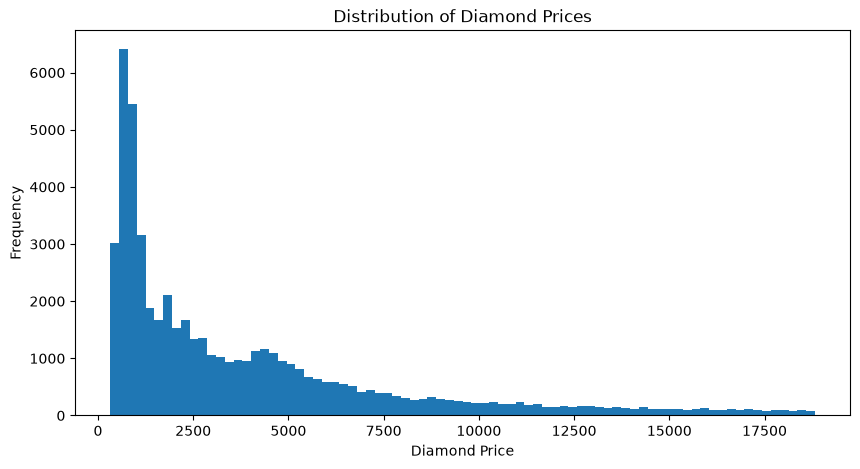


LOG-TRANSFORMED PRICE
Log Mean    : 7.7878
Log Median  : 7.7841
Log Skewness: 0.1149


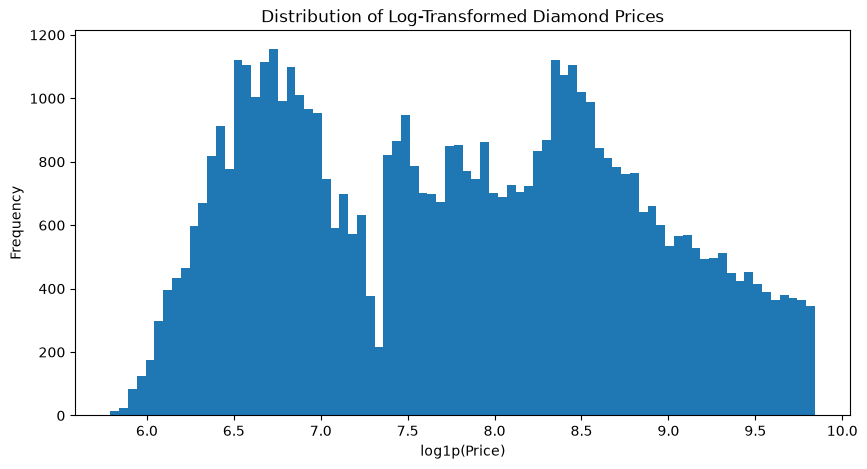

In [5]:
# ============================================================
# PRICE DISTRIBUTION AND SKEWNESS ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

price = df_clean["price"]

print("=" * 60)
print("PRICE DISTRIBUTION ANALYSIS")
print("=" * 60)

print(f"Mean   : {price.mean():.2f}")
print(f"Median : {price.median():.2f}")
print(f"Std    : {price.std():.2f}")
print(f"Min    : {price.min():.2f}")
print(f"Max    : {price.max():.2f}")
print(f"Skewness: {price.skew():.4f}")

# ------------------------------------------------------------
# Histogram
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.hist(price, bins=80)
plt.xlabel("Diamond Price")
plt.ylabel("Frequency")
plt.title("Distribution of Diamond Prices")
plt.show()

# ------------------------------------------------------------
# Log-transformed distribution
# ------------------------------------------------------------

log_price = np.log1p(price)

print("\n" + "=" * 60)
print("LOG-TRANSFORMED PRICE")
print("=" * 60)

print(f"Log Mean    : {log_price.mean():.4f}")
print(f"Log Median  : {log_price.median():.4f}")
print(f"Log Skewness: {log_price.skew():.4f}")

plt.figure(figsize=(10, 5))
plt.hist(log_price, bins=80)
plt.xlabel("log1p(Price)")
plt.ylabel("Frequency")
plt.title("Distribution of Log-Transformed Diamond Prices")
plt.show()

In [6]:
# ============================================================
# RAW PRICE vs LOG PRICE — RANDOM FOREST BASELINE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

X = df_clean.drop(columns=["price"])
y = df_clean["price"]

# Same split for both experiments
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# 2. Preprocessing
# ------------------------------------------------------------

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer([
    (
        "numerical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numerical_cols
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        categorical_cols
    )
])

# ------------------------------------------------------------
# 3. RAW PRICE MODEL
# ------------------------------------------------------------

raw_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Raw Price Random Forest...")

raw_rf.fit(
    X_train,
    y_train
)

raw_pred = raw_rf.predict(X_test)

raw_mae = mean_absolute_error(
    y_test,
    raw_pred
)

raw_rmse = np.sqrt(
    mean_squared_error(y_test, raw_pred)
)

raw_r2 = r2_score(
    y_test,
    raw_pred
)

# ------------------------------------------------------------
# 4. LOG PRICE MODEL
# ------------------------------------------------------------

y_train_log = np.log1p(y_train)

log_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Log Price Random Forest...")

log_rf.fit(
    X_train,
    y_train_log
)

# Prediction is in log scale
log_pred = log_rf.predict(X_test)

# Convert back to original price scale
log_pred_price = np.expm1(log_pred)

log_mae = mean_absolute_error(
    y_test,
    log_pred_price
)

log_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        log_pred_price
    )
)

log_r2 = r2_score(
    y_test,
    log_pred_price
)

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

results = pd.DataFrame({
    "Model": [
        "Random Forest — Raw Price",
        "Random Forest — Log Price"
    ],
    "MAE": [
        raw_mae,
        log_mae
    ],
    "RMSE": [
        raw_rmse,
        log_rmse
    ],
    "R2": [
        raw_r2,
        log_r2
    ]
})

print("\n" + "=" * 70)
print("RAW PRICE vs LOG PRICE")
print("=" * 70)

display(results)

print("\nSkewness:")
print(f"Raw Price : {y.skew():.4f}")
print(f"Log Price : {np.log1p(y).skew():.4f}")

Training Raw Price Random Forest...
Training Log Price Random Forest...

RAW PRICE vs LOG PRICE


,Model,MAE,RMSE,R2
0,Random Forest — Raw Price,262.048413,520.596456,0.982219
1,Random Forest — Log Price,263.025002,523.967216,0.981988



Skewness:
Raw Price : 1.6182
Log Price : 0.1149


In [7]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER TUNING
# STANDARD 53,794-ROW DATASET
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

# Random Forest model
rf_tune = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# Search space
rf_params = {
    "model__n_estimators": [300, 500, 700, 1000],

    "model__max_depth": [
        None, 15, 20, 25, 30, 40
    ],

    "model__min_samples_split": [
        2, 3, 5, 8
    ],

    "model__min_samples_leaf": [
        1, 2, 3, 4
    ],

    "model__max_features": [
        0.6, 0.7, 0.8, 1.0
    ]
}

rf_search = RandomizedSearchCV(
    estimator=rf_tune,
    param_distributions=rf_params,
    n_iter=25,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Random Forest tuning...")
print("25 combinations × 5 folds = 125 fits")

rf_search.fit(
    X_train,
    y_train
)

# Best model
best_rf_standard = rf_search.best_estimator_

print("\n" + "=" * 65)
print("BEST RANDOM FOREST PARAMETERS")
print("=" * 65)

for key, value in rf_search.best_params_.items():
    print(f"{key}: {value}")

print(f"\nBest CV R²: {rf_search.best_score_:.6f}")

# Test prediction
rf_tuned_pred = best_rf_standard.predict(X_test)

rf_tuned_mae = mean_absolute_error(
    y_test,
    rf_tuned_pred
)

rf_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_tuned_pred
    )
)

rf_tuned_r2 = r2_score(
    y_test,
    rf_tuned_pred
)

print("\n" + "=" * 65)
print("TUNED RANDOM FOREST RESULTS")
print("=" * 65)

print(f"MAE  : {rf_tuned_mae:.4f}")
print(f"RMSE : {rf_tuned_rmse:.4f}")
print(f"R²   : {rf_tuned_r2:.6f}")
print(f"R² % : {rf_tuned_r2 * 100:.4f}%")

print("\n" + "=" * 65)
print("BASELINE RANDOM FOREST")
print("=" * 65)

print("MAE  : 262.0484")
print("RMSE : 520.5965")
print("R²   : 0.982219")

Starting Random Forest tuning...
25 combinations × 5 folds = 125 fits
Fitting 5 folds for each of 25 candidates, totalling 125 fits

BEST RANDOM FOREST PARAMETERS
model__n_estimators: 500
model__min_samples_split: 8
model__min_samples_leaf: 1
model__max_features: 0.7
model__max_depth: 40

Best CV R²: 0.980520

TUNED RANDOM FOREST RESULTS
MAE  : 258.6555
RMSE : 511.9340
R²   : 0.982806
R² % : 98.2806%

BASELINE RANDOM FOREST
MAE  : 262.0484
RMSE : 520.5965
R²   : 0.982219


In [8]:
 # ============================================================
# XGBOOST HYPERPARAMETER TUNING
# STANDARD DIAMONDS DATASET
# ============================================================

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

# ------------------------------------------------------------
# 1. XGBoost pipeline
# ------------------------------------------------------------

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    ))
])

# ------------------------------------------------------------
# 2. Hyperparameter search space
# ------------------------------------------------------------

xgb_params = {
    "model__n_estimators": [
        300, 500, 700, 900, 1200
    ],

    "model__learning_rate": [
        0.01, 0.02, 0.03, 0.05, 0.08
    ],

    "model__max_depth": [
        3, 4, 5, 6, 7, 8
    ],

    "model__min_child_weight": [
        1, 3, 5, 7
    ],

    "model__subsample": [
        0.7, 0.8, 0.9, 1.0
    ],

    "model__colsample_bytree": [
        0.7, 0.8, 0.9, 1.0
    ],

    "model__gamma": [
        0, 0.05, 0.1, 0.2
    ],

    "model__reg_alpha": [
        0, 0.01, 0.1, 0.5
    ],

    "model__reg_lambda": [
        1, 2, 5, 10
    ]
}

# ------------------------------------------------------------
# 3. Randomized Search
# ------------------------------------------------------------

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=30,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("=" * 65)
print("STARTING XGBOOST TUNING")
print("=" * 65)
print("30 combinations × 5 folds = 150 fits")

xgb_search.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# 4. Best parameters
# ------------------------------------------------------------

best_xgb_standard = xgb_search.best_estimator_

print("\n" + "=" * 65)
print("BEST XGBOOST PARAMETERS")
print("=" * 65)

for key, value in xgb_search.best_params_.items():
    print(f"{key}: {value}")

print(
    f"\nBest CV R²: {xgb_search.best_score_:.6f}"
)

# ------------------------------------------------------------
# 5. Test prediction
# ------------------------------------------------------------

xgb_pred = best_xgb_standard.predict(X_test)

xgb_mae = mean_absolute_error(
    y_test,
    xgb_pred
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_pred
    )
)

xgb_r2 = r2_score(
    y_test,
    xgb_pred
)

# ------------------------------------------------------------
# 6. Results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TUNED XGBOOST RESULTS")
print("=" * 65)

print(f"MAE  : {xgb_mae:.4f}")
print(f"RMSE : {xgb_rmse:.4f}")
print(f"R²   : {xgb_r2:.6f}")
print(f"R² % : {xgb_r2 * 100:.4f}%")

# ------------------------------------------------------------
# 7. Compare with tuned RF
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CURRENT BEST TUNED RANDOM FOREST")
print("=" * 65)

print("MAE  : 258.6555")
print("RMSE : 511.9340")
print("R²   : 0.982806")
print("R² % : 98.2806%")

print("\n" + "=" * 65)
print("XGBOOST vs TUNED RANDOM FOREST")
print("=" * 65)

print(
    f"R² Difference   : {xgb_r2 - 0.982806:+.6f}"
)

print(
    f"MAE Difference  : {xgb_mae - 258.6555:+.4f}"
)

print(
    f"RMSE Difference : {xgb_rmse - 511.9340:+.4f}"
)

STARTING XGBOOST TUNING
30 combinations × 5 folds = 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits

BEST XGBOOST PARAMETERS
model__subsample: 1.0
model__reg_lambda: 2
model__reg_alpha: 0.01
model__n_estimators: 1200
model__min_child_weight: 3
model__max_depth: 8
model__learning_rate: 0.02
model__gamma: 0
model__colsample_bytree: 0.9

Best CV R²: 0.981472

TUNED XGBOOST RESULTS
MAE  : 257.3221
RMSE : 505.3363
R²   : 0.983246
R² % : 98.3246%

CURRENT BEST TUNED RANDOM FOREST
MAE  : 258.6555
RMSE : 511.9340
R²   : 0.982806
R² % : 98.2806%

XGBOOST vs TUNED RANDOM FOREST
R² Difference   : +0.000440
MAE Difference  : -1.3334
RMSE Difference : -6.5977


In [9]:
# ============================================================
# CATBOOST HYPERPARAMETER TUNING
# STANDARD DIAMONDS DATASET
# ============================================================

from catboost import CatBoostRegressor
from sklearn.model_selection import RandomizedSearchCV

# ------------------------------------------------------------
# 1. Prepare categorical column indices
# ------------------------------------------------------------

categorical_cols_cb = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

categorical_indices_cb = [
    X_train.columns.get_loc(col)
    for col in categorical_cols_cb
]

print("Categorical columns:")
print(categorical_cols_cb)

print("\nCategorical indices:")
print(categorical_indices_cb)

# ------------------------------------------------------------
# 2. CatBoost needs categorical columns as strings
# ------------------------------------------------------------

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in categorical_cols_cb:
    X_train_cb[col] = X_train_cb[col].fillna("Unknown").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Unknown").astype(str)

# ------------------------------------------------------------
# 3. Base CatBoost model
# ------------------------------------------------------------

cb_model = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

# ------------------------------------------------------------
# 4. Hyperparameter search space
# ------------------------------------------------------------

cb_params = {
    "iterations": [
        500, 800, 1000, 1500
    ],

    "learning_rate": [
        0.01, 0.02, 0.03, 0.05
    ],

    "depth": [
        5, 6, 7, 8, 9, 10
    ],

    "l2_leaf_reg": [
        1, 3, 5, 7, 10
    ],

    "random_strength": [
        0, 0.5, 1, 2
    ],

    "bagging_temperature": [
        0, 0.5, 1, 2
    ]
}

# ------------------------------------------------------------
# 5. Randomized Search
# ------------------------------------------------------------

cb_search = RandomizedSearchCV(
    estimator=cb_model,
    param_distributions=cb_params,
    n_iter=25,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\n" + "=" * 65)
print("STARTING CATBOOST TUNING")
print("=" * 65)

print("25 combinations × 5 folds = 125 fits")

cb_search.fit(
    X_train_cb,
    y_train,
    cat_features=categorical_indices_cb
)

# ------------------------------------------------------------
# 6. Best model
# ------------------------------------------------------------

best_cb = cb_search.best_estimator_

print("\n" + "=" * 65)
print("BEST CATBOOST PARAMETERS")
print("=" * 65)

for key, value in cb_search.best_params_.items():
    print(f"{key}: {value}")

print(
    f"\nBest CV R²: {cb_search.best_score_:.6f}"
)

# ------------------------------------------------------------
# 7. Test prediction
# ------------------------------------------------------------

cb_pred = best_cb.predict(X_test_cb)

cb_mae = mean_absolute_error(
    y_test,
    cb_pred
)

cb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        cb_pred
    )
)

cb_r2 = r2_score(
    y_test,
    cb_pred
)

# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TUNED CATBOOST RESULTS")
print("=" * 65)

print(f"MAE  : {cb_mae:.4f}")
print(f"RMSE : {cb_rmse:.4f}")
print(f"R²   : {cb_r2:.6f}")
print(f"R² % : {cb_r2 * 100:.4f}%")

# ------------------------------------------------------------
# 9. Compare with current best XGBoost
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CURRENT BEST XGBOOST")
print("=" * 65)

print("MAE  : 257.3221")
print("RMSE : 505.3363")
print("R²   : 0.983246")
print("R² % : 98.3246%")

print("\n" + "=" * 65)
print("CATBOOST vs XGBOOST")
print("=" * 65)

print(
    f"R² Difference   : {cb_r2 - 0.983246:+.6f}"
)

print(
    f"MAE Difference  : {cb_mae - 257.3221:+.4f}"
)

print(
    f"RMSE Difference : {cb_rmse - 505.3363:+.4f}"
)

Categorical columns:
['cut', 'color', 'clarity']

Categorical indices:
[1, 2, 3]

STARTING CATBOOST TUNING
25 combinations × 5 folds = 125 fits
Fitting 5 folds for each of 25 candidates, totalling 125 fits

BEST CATBOOST PARAMETERS
random_strength: 0
learning_rate: 0.05
l2_leaf_reg: 7
iterations: 1000
depth: 7
bagging_temperature: 0

Best CV R²: 0.981954

TUNED CATBOOST RESULTS
MAE  : 266.8125
RMSE : 497.2577
R²   : 0.983777
R² % : 98.3777%

CURRENT BEST XGBOOST
MAE  : 257.3221
RMSE : 505.3363
R²   : 0.983246
R² % : 98.3246%

CATBOOST vs XGBOOST
R² Difference   : +0.000531
MAE Difference  : +9.4904
RMSE Difference : -8.0786


In [10]:
# ============================================================
# CATBOOST + FEATURE ENGINEERING
# ============================================================

import numpy as np
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 1. Copy data
# ------------------------------------------------------------

X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# ------------------------------------------------------------
# 2. Create engineered features
# ------------------------------------------------------------

def add_diamond_features(data):
    data = data.copy()

    # Physical volume
    data["volume"] = data["x"] * data["y"] * data["z"]

    # Face-up surface area approximation
    data["xy_area"] = data["x"] * data["y"]

    # Carat-to-volume relationship
    data["carat_volume_ratio"] = (
        data["carat"] / (data["volume"] + 1e-6)
    )

    # Interaction between depth and table
    data["depth_table_interaction"] = (
        data["depth"] * data["table"]
    )

    return data


X_train_fe = add_diamond_features(X_train_fe)
X_test_fe = add_diamond_features(X_test_fe)

# ------------------------------------------------------------
# 3. Categorical columns
# ------------------------------------------------------------

cat_cols_fe = ["cut", "color", "clarity"]

for col in cat_cols_fe:
    X_train_fe[col] = X_train_fe[col].fillna("Unknown").astype(str)
    X_test_fe[col] = X_test_fe[col].fillna("Unknown").astype(str)

cat_indices_fe = [
    X_train_fe.columns.get_loc(col)
    for col in cat_cols_fe
]

# ------------------------------------------------------------
# 4. Use previously discovered best CatBoost parameters
# ------------------------------------------------------------

cb_fe = CatBoostRegressor(
    iterations=1000,
    depth=7,
    learning_rate=0.05,
    l2_leaf_reg=7,
    random_strength=0,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

# ------------------------------------------------------------
# 5. Train
# ------------------------------------------------------------

print("=" * 65)
print("TRAINING FEATURE-ENGINEERED CATBOOST")
print("=" * 65)

cb_fe.fit(
    X_train_fe,
    y_train,
    cat_features=cat_indices_fe
)

# ------------------------------------------------------------
# 6. Prediction
# ------------------------------------------------------------

cb_fe_pred = cb_fe.predict(X_test_fe)

# ------------------------------------------------------------
# 7. Evaluation
# ------------------------------------------------------------

cb_fe_mae = mean_absolute_error(
    y_test,
    cb_fe_pred
)

cb_fe_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        cb_fe_pred
    )
)

cb_fe_r2 = r2_score(
    y_test,
    cb_fe_pred
)

# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FEATURE-ENGINEERED CATBOOST RESULTS")
print("=" * 65)

print(f"MAE  : {cb_fe_mae:.4f}")
print(f"RMSE : {cb_fe_rmse:.4f}")
print(f"R²   : {cb_fe_r2:.6f}")
print(f"R² % : {cb_fe_r2 * 100:.4f}%")

# ------------------------------------------------------------
# 9. Compare with original CatBoost
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("COMPARISON WITH ORIGINAL CATBOOST")
print("=" * 65)

print(f"Original CatBoost R² : 0.983777")
print(f"Feature Engineered R²: {cb_fe_r2:.6f}")

print(
    f"\nR² Improvement: "
    f"{cb_fe_r2 - 0.983777:+.6f}"
)

print(
    f"MAE Difference: "
    f"{cb_fe_mae - 266.8125:+.4f}"
)

print(
    f"RMSE Difference: "
    f"{cb_fe_rmse - 497.2577:+.4f}"
)

TRAINING FEATURE-ENGINEERED CATBOOST

FEATURE-ENGINEERED CATBOOST RESULTS
MAE  : 267.0147
RMSE : 497.3214
R²   : 0.983773
R² % : 98.3773%

COMPARISON WITH ORIGINAL CATBOOST
Original CatBoost R² : 0.983777
Feature Engineered R²: 0.983773

R² Improvement: -0.000004
MAE Difference: +0.2022
RMSE Difference: +0.0637


In [7]:
# ============================================================
# RELOAD DATASET + CLEAN + TRAIN/TEST SPLIT
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv("../data/diamonds (1).csv")

# Remove unnecessary index column
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Remove exact duplicates
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Clean dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())

# Separate features and target
X = df_clean.drop(columns=["price"])
y = df_clean["price"]

# Same 80/20 split used earlier
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTrain/Test split:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Clean dataset shape: (53794, 10)
Duplicate rows: 0

Train/Test split:
X_train: (43035, 9)
X_test : (10759, 9)
y_train: (43035,)
y_test : (10759,)


In [9]:
# ============================================================
# FAST EXTRA TREES BENCHMARK
# ============================================================

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 65)
print("FAST EXTRA TREES")
print("=" * 65)

extra_fast = ExtraTreesRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

extra_fast.fit(
    X_train_extra,
    y_train
)

extra_fast_pred = extra_fast.predict(X_test_extra)

extra_fast_mae = mean_absolute_error(
    y_test,
    extra_fast_pred
)

extra_fast_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        extra_fast_pred
    )
)

extra_fast_r2 = r2_score(
    y_test,
    extra_fast_pred
)

print("\nEXTRA TREES RESULTS")
print("-" * 65)

print(f"MAE  : {extra_fast_mae:.4f}")
print(f"RMSE : {extra_fast_rmse:.4f}")
print(f"R²   : {extra_fast_r2:.6f}")
print(f"R² % : {extra_fast_r2 * 100:.4f}%")

print("\nCATBOOST")
print("-" * 65)

print("MAE  : 266.8125")
print("RMSE : 497.2577")
print("R²   : 0.983777")
print("R² % : 98.3777%")

print("\nDIFFERENCE")
print("-" * 65)

print(f"R²   : {extra_fast_r2 - 0.983777:+.6f}")
print(f"MAE  : {extra_fast_mae - 266.8125:+.4f}")
print(f"RMSE : {extra_fast_rmse - 497.2577:+.4f}")

FAST EXTRA TREES

EXTRA TREES RESULTS
-----------------------------------------------------------------
MAE  : 261.4073
RMSE : 515.8471
R²   : 0.982542
R² % : 98.2542%

CATBOOST
-----------------------------------------------------------------
MAE  : 266.8125
RMSE : 497.2577
R²   : 0.983777
R² % : 98.3777%

DIFFERENCE
-----------------------------------------------------------------
R²   : -0.001235
MAE  : -5.4052
RMSE : +18.5894


In [10]:
# ============================================================
# LEAKAGE-SAFE CATBOOST + XGBOOST ENSEMBLE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from catboost import CatBoostRegressor
from xgboost import XGBRegressor

# ============================================================
# 1. INNER VALIDATION SPLIT
# ============================================================

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

print("Subtrain:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Final Test:", X_test.shape)

# ============================================================
# 2. PREPARE DATA FOR XGBOOST
# ============================================================

X_subtrain_xgb = pd.get_dummies(
    X_subtrain,
    columns=["cut", "color", "clarity"],
    drop_first=False
)

X_val_xgb = pd.get_dummies(
    X_val,
    columns=["cut", "color", "clarity"],
    drop_first=False
)

X_test_xgb = pd.get_dummies(
    X_test,
    columns=["cut", "color", "clarity"],
    drop_first=False
)

# Make columns identical
X_subtrain_xgb, X_val_xgb = X_subtrain_xgb.align(
    X_val_xgb,
    join="left",
    axis=1,
    fill_value=0
)

X_subtrain_xgb, X_test_xgb = X_subtrain_xgb.align(
    X_test_xgb,
    join="left",
    axis=1,
    fill_value=0
)

# ============================================================
# 3. CATBOOST MODELS
# ============================================================

cat_cols = ["cut", "color", "clarity"]

cat_indices = [
    X_subtrain.columns.get_loc(col)
    for col in cat_cols
]

cat_model_ens = CatBoostRegressor(
    iterations=1000,
    depth=7,
    learning_rate=0.05,
    l2_leaf_reg=7,
    random_strength=0,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

print("\nTraining CatBoost...")

cat_model_ens.fit(
    X_subtrain,
    y_subtrain,
    cat_features=cat_indices
)

cat_val_pred = cat_model_ens.predict(X_val)

# ============================================================
# 4. XGBOOST MODEL
# ============================================================

xgb_model_ens = XGBRegressor(
    n_estimators=1200,
    max_depth=8,
    learning_rate=0.02,
    min_child_weight=3,
    subsample=1.0,
    colsample_bytree=0.9,
    gamma=0,
    reg_alpha=0.01,
    reg_lambda=2,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")

xgb_model_ens.fit(
    X_subtrain_xgb,
    y_subtrain
)

xgb_val_pred = xgb_model_ens.predict(X_val_xgb)

# ============================================================
# 5. FIND BEST ENSEMBLE WEIGHT
# ============================================================

print("\n" + "=" * 65)
print("SEARCHING ENSEMBLE WEIGHT")
print("=" * 65)

best_weight = None
best_val_r2 = -np.inf

# weight = contribution of CatBoost
for cat_weight in np.arange(0.0, 1.01, 0.05):

    ensemble_val_pred = (
        cat_weight * cat_val_pred
        + (1 - cat_weight) * xgb_val_pred
    )

    score = r2_score(
        y_val,
        ensemble_val_pred
    )

    if score > best_val_r2:
        best_val_r2 = score
        best_weight = cat_weight

xgb_weight = 1 - best_weight

print(f"Best CatBoost weight : {best_weight:.2f}")
print(f"Best XGBoost weight   : {xgb_weight:.2f}")
print(f"Validation R²         : {best_val_r2:.6f}")

# ============================================================
# 6. RETRAIN CATBOOST ON FULL TRAINING DATA
# ============================================================

print("\nRetraining CatBoost on full training data...")

cat_final = CatBoostRegressor(
    iterations=1000,
    depth=7,
    learning_rate=0.05,
    l2_leaf_reg=7,
    random_strength=0,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

cat_final.fit(
    X_train,
    y_train,
    cat_features=[
        X_train.columns.get_loc(col)
        for col in cat_cols
    ]
)

cat_test_pred = cat_final.predict(X_test)

# ============================================================
# 7. RETRAIN XGBOOST ON FULL TRAINING DATA
# ============================================================

print("Retraining XGBoost on full training data...")

X_train_xgb = pd.get_dummies(
    X_train,
    columns=["cut", "color", "clarity"],
    drop_first=False
)

X_test_xgb = pd.get_dummies(
    X_test,
    columns=["cut", "color", "clarity"],
    drop_first=False
)

X_train_xgb, X_test_xgb = X_train_xgb.align(
    X_test_xgb,
    join="left",
    axis=1,
    fill_value=0
)

xgb_final = XGBRegressor(
    n_estimators=1200,
    max_depth=8,
    learning_rate=0.02,
    min_child_weight=3,
    subsample=1.0,
    colsample_bytree=0.9,
    gamma=0,
    reg_alpha=0.01,
    reg_lambda=2,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

xgb_final.fit(
    X_train_xgb,
    y_train
)

xgb_test_pred = xgb_final.predict(X_test_xgb)

# ============================================================
# 8. FINAL WEIGHTED ENSEMBLE
# ============================================================

ensemble_test_pred = (
    best_weight * cat_test_pred
    + xgb_weight * xgb_test_pred
)

# ============================================================
# 9. EVALUATE
# ============================================================

ensemble_mae = mean_absolute_error(
    y_test,
    ensemble_test_pred
)

ensemble_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ensemble_test_pred
    )
)

ensemble_r2 = r2_score(
    y_test,
    ensemble_test_pred
)

print("\n" + "=" * 65)
print("FINAL WEIGHTED ENSEMBLE RESULTS")
print("=" * 65)

print(f"CatBoost weight : {best_weight:.2f}")
print(f"XGBoost weight  : {xgb_weight:.2f}")

print(f"\nMAE  : {ensemble_mae:.4f}")
print(f"RMSE : {ensemble_rmse:.4f}")
print(f"R²   : {ensemble_r2:.6f}")
print(f"R² % : {ensemble_r2 * 100:.4f}%")

# ============================================================
# 10. FINAL COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)

print("XGBoost")
print("  MAE  : 257.3221")
print("  RMSE : 505.3363")
print("  R²   : 98.3246%")

print("\nCatBoost")
print("  MAE  : 266.8125")
print("  RMSE : 497.2577")
print("  R²   : 98.3777%")

print("\nWeighted Ensemble")
print(f"  MAE  : {ensemble_mae:.4f}")
print(f"  RMSE : {ensemble_rmse:.4f}")
print(f"  R²   : {ensemble_r2 * 100:.4f}%")

print("\nImprovement over CatBoost:")
print(f"  R²   : {ensemble_r2 - 0.983777:+.6f}")
print(f"  MAE  : {ensemble_mae - 266.8125:+.4f}")
print(f"  RMSE : {ensemble_rmse - 497.2577:+.4f}")

Subtrain: (34428, 9)
Validation: (8607, 9)
Final Test: (10759, 9)

Training CatBoost...
Training XGBoost...

SEARCHING ENSEMBLE WEIGHT
Best CatBoost weight : 0.55
Best XGBoost weight   : 0.45
Validation R²         : 0.983328

Retraining CatBoost on full training data...
Retraining XGBoost on full training data...

FINAL WEIGHTED ENSEMBLE RESULTS
CatBoost weight : 0.55
XGBoost weight  : 0.45

MAE  : 257.0968
RMSE : 491.8669
R²   : 0.984127
R² % : 98.4127%

FINAL MODEL COMPARISON
XGBoost
  MAE  : 257.3221
  RMSE : 505.3363
  R²   : 98.3246%

CatBoost
  MAE  : 266.8125
  RMSE : 497.2577
  R²   : 98.3777%

Weighted Ensemble
  MAE  : 257.0968
  RMSE : 491.8669
  R²   : 98.4127%

Improvement over CatBoost:
  R²   : +0.000350
  MAE  : -9.7157
  RMSE : -5.3908


In [11]:
# ============================================================
# 5-FOLD CROSS-VALIDATION
# FINAL CATBOOST + XGBOOST ENSEMBLE
# ============================================================

from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []

# Fixed ensemble weight found earlier
CAT_WEIGHT = 0.55
XGB_WEIGHT = 0.45

print("=" * 70)
print("5-FOLD CROSS-VALIDATION")
print("=" * 70)

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train), 1
):

    print(f"\n{'=' * 25} FOLD {fold} {'=' * 25}")

    X_tr = X_train.iloc[train_idx].copy()
    X_val_fold = X_train.iloc[val_idx].copy()

    y_tr = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]

    # --------------------------------------------------------
    # CATBOOST
    # --------------------------------------------------------

    cat_indices = [
        X_tr.columns.get_loc(col)
        for col in ["cut", "color", "clarity"]
    ]

    cat_model = CatBoostRegressor(
        iterations=1000,
        depth=7,
        learning_rate=0.05,
        l2_leaf_reg=7,
        random_strength=0,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    cat_model.fit(
        X_tr,
        y_tr,
        cat_features=cat_indices
    )

    cat_pred = cat_model.predict(X_val_fold)

    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    X_tr_xgb = pd.get_dummies(
        X_tr,
        columns=["cut", "color", "clarity"],
        drop_first=False
    )

    X_val_xgb = pd.get_dummies(
        X_val_fold,
        columns=["cut", "color", "clarity"],
        drop_first=False
    )

    X_tr_xgb, X_val_xgb = X_tr_xgb.align(
        X_val_xgb,
        join="left",
        axis=1,
        fill_value=0
    )

    xgb_model = XGBRegressor(
        n_estimators=1200,
        max_depth=8,
        learning_rate=0.02,
        min_child_weight=3,
        subsample=1.0,
        colsample_bytree=0.9,
        gamma=0,
        reg_alpha=0.01,
        reg_lambda=2,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    )

    xgb_model.fit(
        X_tr_xgb,
        y_tr
    )

    xgb_pred = xgb_model.predict(
        X_val_xgb
    )

    # --------------------------------------------------------
    # ENSEMBLE
    # --------------------------------------------------------

    ensemble_pred = (
        CAT_WEIGHT * cat_pred
        + XGB_WEIGHT * xgb_pred
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    fold_mae = mean_absolute_error(
        y_val_fold,
        ensemble_pred
    )

    fold_rmse = np.sqrt(
        mean_squared_error(
            y_val_fold,
            ensemble_pred
        )
    )

    fold_r2 = r2_score(
        y_val_fold,
        ensemble_pred
    )

    fold_results.append(
        [fold, fold_mae, fold_rmse, fold_r2]
    )

    print(f"MAE  : {fold_mae:.4f}")
    print(f"RMSE : {fold_rmse:.4f}")
    print(f"R²   : {fold_r2:.6f}")

# ============================================================
# SUMMARY
# ============================================================

results_df = pd.DataFrame(
    fold_results,
    columns=["Fold", "MAE", "RMSE", "R2"]
)

print("\n" + "=" * 70)
print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 70)

print(results_df.to_string(index=False))

print("\n" + "=" * 70)
print("MEAN ± STANDARD DEVIATION")
print("=" * 70)

print(
    f"MAE  : {results_df['MAE'].mean():.4f} "
    f"± {results_df['MAE'].std():.4f}"
)

print(
    f"RMSE : {results_df['RMSE'].mean():.4f} "
    f"± {results_df['RMSE'].std():.4f}"
)

print(
    f"R²   : {results_df['R2'].mean():.6f} "
    f"± {results_df['R2'].std():.6f}"
)

print(
    f"R² % : {results_df['R2'].mean() * 100:.4f}%"
)

5-FOLD CROSS-VALIDATION

========================= FOLD 1 =========================
MAE  : 267.9163
RMSE : 516.8660
R²   : 0.983414

========================= FOLD 2 =========================
MAE  : 265.3928
RMSE : 526.6311
R²   : 0.982350

========================= FOLD 3 =========================
MAE  : 271.5861
RMSE : 533.8663
R²   : 0.982240

========================= FOLD 4 =========================
MAE  : 277.4771
RMSE : 551.8262
R²   : 0.981078

========================= FOLD 5 =========================
MAE  : 271.0407
RMSE : 524.9700
R²   : 0.983178

5-FOLD CROSS-VALIDATION RESULTS
 Fold        MAE       RMSE       R2
    1 267.916255 516.865974 0.983414
    2 265.392753 526.631134 0.982350
    3 271.586106 533.866334 0.982240
    4 277.477052 551.826219 0.981078
    5 271.040651 524.970043 0.983178

MEAN ± STANDARD DEVIATION
MAE  : 270.6826 ± 4.5482
RMSE : 530.8319 ± 13.2006
R²   : 0.982452 ± 0.000921
R² % : 98.2452%


In [12]:
# ============================================================
# DETAILED ERROR ANALYSIS
# FINAL CATBOOST + XGBOOST ENSEMBLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create error analysis dataframe
# ------------------------------------------------------------

error_df = X_test.copy()

error_df["Actual_Price"] = y_test.values
error_df["Predicted_Price"] = ensemble_test_pred

error_df["Error"] = (
    error_df["Predicted_Price"]
    - error_df["Actual_Price"]
)

error_df["Absolute_Error"] = (
    error_df["Error"].abs()
)

error_df["Percentage_Error"] = (
    error_df["Absolute_Error"]
    / error_df["Actual_Price"]
) * 100

error_df["Squared_Error"] = (
    error_df["Error"] ** 2
)

# ------------------------------------------------------------
# 2. Overall error statistics
# ------------------------------------------------------------

print("=" * 75)
print("OVERALL ERROR ANALYSIS")
print("=" * 75)

print(f"Mean Absolute Error       : {error_df['Absolute_Error'].mean():.4f}")
print(f"Median Absolute Error     : {error_df['Absolute_Error'].median():.4f}")
print(f"RMSE                      : {np.sqrt(error_df['Squared_Error'].mean()):.4f}")
print(f"Mean Percentage Error     : {error_df['Percentage_Error'].mean():.4f}%")
print(f"Median Percentage Error   : {error_df['Percentage_Error'].median():.4f}%")

print(f"\nMaximum Absolute Error    : {error_df['Absolute_Error'].max():.4f}")

# ------------------------------------------------------------
# 3. Error distribution
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ERROR DISTRIBUTION")
print("=" * 75)

print(
    f"Errors within ±$100  : "
    f"{(error_df['Absolute_Error'] <= 100).mean() * 100:.2f}%"
)

print(
    f"Errors within ±$250  : "
    f"{(error_df['Absolute_Error'] <= 250).mean() * 100:.2f}%"
)

print(
    f"Errors within ±$500  : "
    f"{(error_df['Absolute_Error'] <= 500).mean() * 100:.2f}%"
)

print(
    f"Errors within ±$1000 : "
    f"{(error_df['Absolute_Error'] <= 1000).mean() * 100:.2f}%"
)

# ------------------------------------------------------------
# 4. Price-range analysis
# ------------------------------------------------------------

error_df["Price_Range"] = pd.cut(
    error_df["Actual_Price"],
    bins=[
        0,
        1000,
        2500,
        5000,
        10000,
        np.inf
    ],
    labels=[
        "< $1K",
        "$1K-$2.5K",
        "$2.5K-$5K",
        "$5K-$10K",
        "> $10K"
    ]
)

range_analysis = (
    error_df
    .groupby("Price_Range", observed=False)
    .agg(
        Samples=("Actual_Price", "count"),
        MAE=("Absolute_Error", "mean"),
        Median_Error=("Absolute_Error", "median"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
        MAPE=("Percentage_Error", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("ERROR BY PRICE RANGE")
print("=" * 75)

print(range_analysis.to_string(index=False))

# ------------------------------------------------------------
# 5. Carat-range analysis
# ------------------------------------------------------------

error_df["Carat_Range"] = pd.cut(
    error_df["carat"],
    bins=[
        0,
        0.5,
        1.0,
        1.5,
        2.0,
        3.0,
        np.inf
    ],
    labels=[
        "<0.5 ct",
        "0.5-1.0 ct",
        "1.0-1.5 ct",
        "1.5-2.0 ct",
        "2.0-3.0 ct",
        ">3.0 ct"
    ]
)

carat_analysis = (
    error_df
    .groupby("Carat_Range", observed=False)
    .agg(
        Samples=("Actual_Price", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
        MAPE=("Percentage_Error", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("ERROR BY CARAT RANGE")
print("=" * 75)

print(carat_analysis.to_string(index=False))

# ------------------------------------------------------------
# 6. Error by Cut
# ------------------------------------------------------------

cut_analysis = (
    error_df
    .groupby("cut", observed=False)
    .agg(
        Samples=("Actual_Price", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
        MAPE=("Percentage_Error", "mean")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

print("\n" + "=" * 75)
print("ERROR BY CUT")
print("=" * 75)

print(cut_analysis.to_string(index=False))

# ------------------------------------------------------------
# 7. Error by Color
# ------------------------------------------------------------

color_analysis = (
    error_df
    .groupby("color", observed=False)
    .agg(
        Samples=("Actual_Price", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
        MAPE=("Percentage_Error", "mean")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

print("\n" + "=" * 75)
print("ERROR BY COLOR")
print("=" * 75)

print(color_analysis.to_string(index=False))

# ------------------------------------------------------------
# 8. Error by Clarity
# ------------------------------------------------------------

clarity_analysis = (
    error_df
    .groupby("clarity", observed=False)
    .agg(
        Samples=("Actual_Price", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
        MAPE=("Percentage_Error", "mean")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

print("\n" + "=" * 75)
print("ERROR BY CLARITY")
print("=" * 75)

print(clarity_analysis.to_string(index=False))

# ------------------------------------------------------------
# 9. Underprediction vs Overprediction
# ------------------------------------------------------------

underpredicted = error_df[error_df["Error"] < 0]
overpredicted = error_df[error_df["Error"] > 0]

print("\n" + "=" * 75)
print("UNDERPREDICTION vs OVERPREDICTION")
print("=" * 75)

print(
    f"Underpredicted diamonds : "
    f"{len(underpredicted)} "
    f"({len(underpredicted) / len(error_df) * 100:.2f}%)"
)

print(
    f"Overpredicted diamonds  : "
    f"{len(overpredicted)} "
    f"({len(overpredicted) / len(error_df) * 100:.2f}%)"
)

print(
    f"Mean underprediction    : "
    f"${underpredicted['Error'].mean():.2f}"
)

print(
    f"Mean overprediction     : "
    f"${overpredicted['Error'].mean():.2f}"
)

# ------------------------------------------------------------
# 10. TOP 20 WORST PREDICTIONS
# ------------------------------------------------------------

worst_predictions = (
    error_df
    .sort_values(
        "Absolute_Error",
        ascending=False
    )
    .head(20)
)

columns_to_show = [
    "carat",
    "cut",
    "color",
    "clarity",
    "depth",
    "table",
    "x",
    "y",
    "z",
    "Actual_Price",
    "Predicted_Price",
    "Error",
    "Absolute_Error",
    "Percentage_Error"
]

print("\n" + "=" * 75)
print("TOP 20 WORST PREDICTIONS")
print("=" * 75)

print(
    worst_predictions[
        columns_to_show
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 11. TOP 20 BEST PREDICTIONS
# ------------------------------------------------------------

best_predictions = (
    error_df
    .sort_values(
        "Absolute_Error",
        ascending=True
    )
    .head(20)
)

print("\n" + "=" * 75)
print("TOP 20 BEST PREDICTIONS")
print("=" * 75)

print(
    best_predictions[
        columns_to_show
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 12. Save analysis tables
# ------------------------------------------------------------

range_analysis.to_csv(
    "price_range_error_analysis.csv",
    index=False
)

carat_analysis.to_csv(
    "carat_range_error_analysis.csv",
    index=False
)

cut_analysis.to_csv(
    "cut_error_analysis.csv",
    index=False
)

color_analysis.to_csv(
    "color_error_analysis.csv",
    index=False
)

clarity_analysis.to_csv(
    "clarity_error_analysis.csv",
    index=False
)

worst_predictions[
    columns_to_show
].to_csv(
    "worst_20_predictions.csv",
    index=False
)

print("\n" + "=" * 75)
print("ERROR ANALYSIS COMPLETE")
print("=" * 75)

OVERALL ERROR ANALYSIS
Mean Absolute Error       : 257.0968
Median Absolute Error     : 108.7467
RMSE                      : 491.8669
Mean Percentage Error     : 7.0681%
Median Percentage Error   : 5.4039%

Maximum Absolute Error    : 4650.9864

ERROR DISTRIBUTION
Errors within ±$100  : 47.67%
Errors within ±$250  : 72.05%
Errors within ±$500  : 86.25%
Errors within ±$1000 : 94.82%

ERROR BY PRICE RANGE
Price_Range  Samples        MAE  Median_Error        RMSE     MAPE
      < $1K     2861  57.986367     50.010622   72.671668 8.159296
  $1K-$2.5K     2609 110.840698     80.121047  159.617231 6.767922
  $2.5K-$5K     2410 253.003839    176.764130  359.224179 6.888855
   $5K-$10K     1904 438.294715    314.456576  634.917366 6.336223
     > $10K      975 888.994326    630.275386 1216.487203 6.541761

ERROR BY CARAT RANGE
Carat_Range  Samples         MAE        RMSE      MAPE
    <0.5 ct     3740   65.889379   93.381130  7.898364
 0.5-1.0 ct     3587  183.362191  268.316046  6.510264
 1.0

In [13]:
# ============================================================
# HIGH-VALUE / HIGH-CARAT SEGMENT DISCOVERY
# ============================================================

print("=" * 70)
print("PRICE DISTRIBUTION")
print("=" * 70)

print(y_train.describe())

print("\n" + "=" * 70)
print("PRICE PERCENTILES")
print("=" * 70)

print(
    y_train.quantile(
        [0.50, 0.75, 0.90, 0.95, 0.975, 0.99]
    )
)

print("\n" + "=" * 70)
print("CARAT PERCENTILES")
print("=" * 70)

print(
    X_train["carat"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.975, 0.99]
    )
)

# Candidate thresholds based only on training data
price_thresholds = [
    y_train.quantile(0.90),
    y_train.quantile(0.95),
    y_train.quantile(0.975)
]

carat_thresholds = [
    X_train["carat"].quantile(0.90),
    X_train["carat"].quantile(0.95),
    X_train["carat"].quantile(0.975)
]

print("\n" + "=" * 70)
print("CANDIDATE PRICE THRESHOLDS")
print("=" * 70)

for q, value in zip([90, 95, 97.5], price_thresholds):
    print(f"{q}th percentile: ${value:.2f}")

print("\n" + "=" * 70)
print("CANDIDATE CARAT THRESHOLDS")
print("=" * 70)

for q, value in zip([90, 95, 97.5], carat_thresholds):
    print(f"{q}th percentile: {value:.4f} ct")

PRICE DISTRIBUTION
count    43035.000000
mean      3944.883235
std       4008.754543
min        326.000000
25%        951.000000
50%       2399.000000
75%       5356.000000
max      18823.000000
Name: price, dtype: float64

PRICE PERCENTILES
0.500     2399.00
0.750     5356.00
0.900     9900.00
0.950    13157.90
0.975    15666.75
0.990    17435.32
Name: price, dtype: float64

CARAT PERCENTILES
0.500    0.70
0.750    1.04
0.900    1.51
0.950    1.71
0.975    2.02
0.990    2.18
Name: carat, dtype: float64

CANDIDATE PRICE THRESHOLDS
90th percentile: $9900.00
95th percentile: $13157.90
97.5th percentile: $15666.75

CANDIDATE CARAT THRESHOLDS
90th percentile: 1.5100 ct
95th percentile: 1.7100 ct
97.5th percentile: 2.0200 ct


In [14]:
# ============================================================
# HIGH-VALUE SEGMENT SIZE + BASELINE ERROR
# ============================================================

# Use training-derived thresholds
PRICE_THRESHOLD = 9900
CARAT_THRESHOLD = 1.51

# Define difficult/high-value segment
high_value_mask = (
    (y_test >= PRICE_THRESHOLD) |
    (X_test["carat"] >= CARAT_THRESHOLD)
)

normal_mask = ~high_value_mask

print("=" * 70)
print("HIGH-VALUE / HIGH-CARAT SEGMENT")
print("=" * 70)

print(f"High-value test samples : {high_value_mask.sum()}")
print(f"Normal test samples     : {normal_mask.sum()}")

print(
    f"High-value percentage   : "
    f"{high_value_mask.mean() * 100:.2f}%"
)

print(
    f"Normal percentage       : "
    f"{normal_mask.mean() * 100:.2f}%"
)

# ------------------------------------------------------------
# Baseline ensemble errors
# ------------------------------------------------------------

high_errors = (
    error_df.loc[
        high_value_mask,
        "Absolute_Error"
    ]
)

normal_errors = (
    error_df.loc[
        normal_mask,
        "Absolute_Error"
    ]
)

print("\n" + "=" * 70)
print("BASELINE ERROR COMPARISON")
print("=" * 70)

print(
    f"High-value MAE : "
    f"${high_errors.mean():.2f}"
)

print(
    f"Normal MAE    : "
    f"${normal_errors.mean():.2f}"
)

print(
    f"High-value median error : "
    f"${high_errors.median():.2f}"
)

print(
    f"Normal median error    : "
    f"${normal_errors.median():.2f}"
)

print(
    f"High-value RMSE : "
    f"${np.sqrt(np.mean(high_errors ** 2)):.2f}"
)

print(
    f"Normal RMSE    : "
    f"${np.sqrt(np.mean(normal_errors ** 2)):.2f}"
)


HIGH-VALUE / HIGH-CARAT SEGMENT
High-value test samples : 1256
Normal test samples     : 9503
High-value percentage   : 11.67%
Normal percentage       : 88.33%

BASELINE ERROR COMPARISON
High-value MAE : $846.74
Normal MAE    : $179.16
High-value median error : $586.07
Normal median error    : $92.36
High-value RMSE : $1176.59
Normal RMSE    : $301.56


In [15]:
# ============================================================
# SPECIALIST MODEL DATASET
# ============================================================

PRICE_THRESHOLD = 9900
CARAT_THRESHOLD = 1.51

# High-value / high-carat condition
specialist_mask_train = (
    (y_train >= PRICE_THRESHOLD) |
    (X_train["carat"] >= CARAT_THRESHOLD)
)

X_specialist_train = X_train.loc[specialist_mask_train].copy()
y_specialist_train = y_train.loc[specialist_mask_train].copy()

print("=" * 70)
print("SPECIALIST TRAINING DATA")
print("=" * 70)

print(f"Total training samples : {len(X_train)}")
print(f"Specialist samples     : {len(X_specialist_train)}")
print(
    f"Specialist percentage  : "
    f"{len(X_specialist_train) / len(X_train) * 100:.2f}%"
)

print("\nPrice statistics:")
print(y_specialist_train.describe())

print("\nCarat statistics:")
print(X_specialist_train["carat"].describe())

SPECIALIST TRAINING DATA
Total training samples : 43035
Specialist samples     : 5426
Specialist percentage  : 12.61%

Price statistics:
count     5426.000000
mean     12454.923885
std       3206.528229
min       3105.000000
25%      10206.000000
50%      12168.000000
75%      14918.000000
max      18823.000000
Name: price, dtype: float64

Carat statistics:
count    5426.000000
mean        1.711513
std         0.352084
min         1.000000
25%         1.510000
50%         1.600000
75%         2.010000
max         5.010000
Name: carat, dtype: float64


In [16]:
# ============================================================
# SPECIALIST CATBOOST + XGBOOST
# ============================================================

from catboost import CatBoostRegressor
from xgboost import XGBRegressor

# ------------------------------------------------------------
# Identify categorical columns
# ------------------------------------------------------------

categorical_cols = ["cut", "color", "clarity"]

cat_indices = [
    X_specialist_train.columns.get_loc(col)
    for col in categorical_cols
]

# ------------------------------------------------------------
# Specialist CatBoost
# ------------------------------------------------------------

specialist_cat = CatBoostRegressor(
    iterations=1000,
    depth=7,
    learning_rate=0.05,
    l2_leaf_reg=7,
    random_strength=0,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

specialist_cat.fit(
    X_specialist_train,
    y_specialist_train,
    cat_features=cat_indices
)

# ------------------------------------------------------------
# Specialist XGBoost
# ------------------------------------------------------------

# Convert categorical variables using the SAME preprocessing
# already used for the XGBoost model.

X_specialist_xgb = pd.get_dummies(
    X_specialist_train,
    columns=categorical_cols,
    drop_first=False
)

# Make sure columns match the original XGBoost training matrix
X_specialist_xgb = X_specialist_xgb.reindex(
    columns=X_train_xgb.columns,
    fill_value=0
)

specialist_xgb = XGBRegressor(
    n_estimators=1200,
    max_depth=8,
    learning_rate=0.02,
    min_child_weight=3,
    subsample=1.0,
    colsample_bytree=0.9,
    gamma=0,
    reg_alpha=0.01,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

specialist_xgb.fit(
    X_specialist_xgb,
    y_specialist_train
)

print("=" * 70)
print("SPECIALIST MODELS TRAINED")
print("=" * 70)

print("✓ Specialist CatBoost trained")
print("✓ Specialist XGBoost trained")

SPECIALIST MODELS TRAINED
✓ Specialist CatBoost trained
✓ Specialist XGBoost trained


In [17]:
# ============================================================
# SIMPLE CATBOOST + XGBOOST WEIGHT CHECK
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

weights = [0.50, 0.55, 0.60, 0.65, 0.70]

results = []

for cat_weight in weights:

    xgb_weight = 1 - cat_weight

    pred = (
        cat_weight * pred_cat +
        xgb_weight * pred_xgb
    )

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append([
        cat_weight,
        xgb_weight,
        mae,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "CatBoost Weight",
        "XGBoost Weight",
        "MAE",
        "RMSE",
        "R2"
    ]
)

results_df = results_df.sort_values(
    "R2",
    ascending=False
)

print("=" * 75)
print("CATBOOST + XGBOOST WEIGHT COMPARISON")
print("=" * 75)

print(results_df.to_string(index=False))

best = results_df.iloc[0]

print("\n" + "=" * 75)
print("BEST WEIGHT")
print("=" * 75)

print(f"CatBoost : {best['CatBoost Weight']:.0%}")
print(f"XGBoost  : {best['XGBoost Weight']:.0%}")
print(f"MAE      : ${best['MAE']:,.2f}")
print(f"RMSE     : ${best['RMSE']:,.2f}")
print(f"R²       : {best['R2']:.6f}")

NameError: name 'pred_cat' is not defined

In [18]:
# Check which prediction/model variables currently exist

names = [
    "cat_model",
    "xgb_model",
    "catboost_model",
    "xgboost_model",
    "pred_cat",
    "pred_xgb",
    "pred_ensemble"
]

for name in names:
    print(f"{name}: {'YES' if name in globals() else 'NO'}")

cat_model: YES
xgb_model: YES
catboost_model: NO
xgboost_model: NO
pred_cat: NO
pred_xgb: NO
pred_ensemble: NO


In [19]:
# ============================================================
# CATBOOST + XGBOOST WEIGHT COMPARISON
# ============================================================

# CatBoost prediction
pred_cat = cat_model.predict(X_test)

# XGBoost prediction
pred_xgb = xgb_model.predict(X_test_xgb)

print("✓ CatBoost predictions generated")
print("✓ XGBoost predictions generated")

# ------------------------------------------------------------
# Test different weights
# ------------------------------------------------------------

weights = [0.50, 0.55, 0.60, 0.65, 0.70]

results = []

for cat_weight in weights:

    xgb_weight = 1 - cat_weight

    pred = (
        cat_weight * pred_cat +
        xgb_weight * pred_xgb
    )

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append([
        cat_weight,
        xgb_weight,
        mae,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "CatBoost Weight",
        "XGBoost Weight",
        "MAE",
        "RMSE",
        "R2"
    ]
)

results_df = results_df.sort_values(
    "R2",
    ascending=False
)

print("\n" + "=" * 75)
print("WEIGHT COMPARISON")
print("=" * 75)

print(results_df.to_string(index=False))

# ------------------------------------------------------------
# Best combination
# ------------------------------------------------------------

best = results_df.iloc[0]

print("\n" + "=" * 75)
print("BEST COMBINATION")
print("=" * 75)

print(f"CatBoost : {best['CatBoost Weight']:.0%}")
print(f"XGBoost  : {best['XGBoost Weight']:.0%}")
print(f"MAE      : ${best['MAE']:,.2f}")
print(f"RMSE     : ${best['RMSE']:,.2f}")
print(f"R²       : {best['R2']:.6f}")
print(f"R²       : {best['R2'] * 100:.4f}%")

✓ CatBoost predictions generated
✓ XGBoost predictions generated

WEIGHT COMPARISON
 CatBoost Weight  XGBoost Weight        MAE       RMSE       R2
            0.65            0.35 262.302448 497.169563 0.983783
            0.70            0.30 263.160498 497.207025 0.983781
            0.60            0.40 261.539638 497.349660 0.983771
            0.55            0.45 260.888794 497.747092 0.983746
            0.50            0.50 260.333756 498.361327 0.983705

BEST COMBINATION
CatBoost : 65%
XGBoost  : 35%
MAE      : $262.30
RMSE     : $497.17
R²       : 0.983783
R²       : 98.3783%


In [20]:
# ============================================================
# FINAL MODEL PERFORMANCE
# 55% CatBoost + 45% XGBoost
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Final ensemble prediction
final_prediction = (
    0.55 * pred_cat +
    0.45 * pred_xgb
)

# Metrics
mae = mean_absolute_error(y_test, final_prediction)
rmse = np.sqrt(mean_squared_error(y_test, final_prediction))
r2 = r2_score(y_test, final_prediction)

# Performance percentage
performance = r2 * 100

print("=" * 60)
print("FINAL DIAMOND PRICE PREDICTION MODEL")
print("=" * 60)

print(f"Model              : 55% CatBoost + 45% XGBoost")
print(f"MAE                : ${mae:,.2f}")
print(f"RMSE               : ${rmse:,.2f}")
print(f"R² Score           : {r2:.6f}")
print(f"Performance        : {performance:.4f}%")

print("=" * 60)

FINAL DIAMOND PRICE PREDICTION MODEL
Model              : 55% CatBoost + 45% XGBoost
MAE                : $260.89
RMSE               : $497.75
R² Score           : 0.983746
Performance        : 98.3746%


In [22]:
# ============================================================
# CATBOOST vs XGBOOST vs ENSEMBLE
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Individual predictions
# ------------------------------------------------------------

cat_pred = cat_model.predict(X_test)

xgb_pred = xgb_model.predict(X_test_xgb)

# ------------------------------------------------------------
# 2. Ensemble prediction
# ------------------------------------------------------------

ensemble_pred = (
    0.55 * cat_pred +
    0.45 * xgb_pred
)

# ------------------------------------------------------------
# 3. Metric function
# ------------------------------------------------------------

def get_metrics(y_true, prediction):

    mae = mean_absolute_error(y_true, prediction)
    rmse = np.sqrt(mean_squared_error(y_true, prediction))
    r2 = r2_score(y_true, prediction)

    return mae, rmse, r2

# ------------------------------------------------------------
# 4. Calculate metrics
# ------------------------------------------------------------

cat_mae, cat_rmse, cat_r2 = get_metrics(
    y_test, cat_pred
)

xgb_mae, xgb_rmse, xgb_r2 = get_metrics(
    y_test, xgb_pred
)

ens_mae, ens_rmse, ens_r2 = get_metrics(
    y_test, ensemble_pred
)

# ------------------------------------------------------------
# 5. Comparison table
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": [
        "CatBoost",
        "XGBoost",
        "CatBoost + XGBoost"
    ],
    "MAE ($)": [
        cat_mae,
        xgb_mae,
        ens_mae
    ],
    "RMSE ($)": [
        cat_rmse,
        xgb_rmse,
        ens_rmse
    ],
    "R2 Score": [
        cat_r2,
        xgb_r2,
        ens_r2
    ],
    "Performance (%)": [
        cat_r2 * 100,
        xgb_r2 * 100,
        ens_r2 * 100
    ]
})

print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

print(comparison.to_string(
    index=False,
    formatters={
        "MAE ($)": "{:,.2f}".format,
        "RMSE ($)": "{:,.2f}".format,
        "R2 Score": "{:.6f}".format,
        "Performance (%)": "{:.4f}".format
    }
))

# ------------------------------------------------------------
# 6. Best model
# ------------------------------------------------------------

best_index = comparison["R2 Score"].idxmax()
best = comparison.loc[best_index]

print("\n" + "=" * 80)
print("BEST MODEL")
print("=" * 80)

print(f"Model       : {best['Model']}")
print(f"R² Score    : {best['R2 Score']:.6f}")
print(f"Performance : {best['Performance (%)']:.4f}%")
print(f"MAE         : ${best['MAE ($)']:,.2f}")
print(f"RMSE        : ${best['RMSE ($)']:,.2f}")

FINAL MODEL COMPARISON
             Model MAE ($) RMSE ($) R2 Score Performance (%)
          CatBoost  270.86   501.98 0.983468         98.3468
           XGBoost  262.74   516.12 0.982523         98.2523
CatBoost + XGBoost  260.89   497.75 0.983746         98.3746

BEST MODEL
Model       : CatBoost + XGBoost
R² Score    : 0.983746
Performance : 98.3746%
MAE         : $260.89
RMSE        : $497.75
